# Covering fraction and N_HI across realizations

Absorber covering fractions and N_HI distributions vs impact parameter, over the 5
realizations of one simulation (`SIM_NAME` in CELL 2, default TNG50-2). The spread
between realizations is the uncertainty band; `16_bootstrap.ipynb` gives the bootstrap one.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import matplotlib.patches as patches


# ==============================================================================
# CELL 1: CONFIGURATION & STYLE
# ==============================================================================
# Absorber-class colours -- single source of truth for every figure in this
# notebook that colours by absorber class (CELL 4's cat_styles and the
# ridgeline's background bands both reuse this dict). Same mapping used in
# 14_Temperatures.ipynb's CLASS_COLORS: forest E69F00, LLS 56B4E9, Sub-DLA
# 009E73, Small-DLA F0E442, Large-DLA 0072B2.
CLASS_COLORS = {
    'Forest':    '#E69F00',
    'LLS':       '#56B4E9',
    'Sub_DLA':   '#009E73',
    'Small_DLA': '#F0E442',
    'Large_DLA': '#0072B2',
}


def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
%load_ext autoreload
%autoreload 2
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


In [2]:
# ==============================================================================
# CELL 2: SIMULATION AND PATHS
# ==============================================================================
from pathlib import Path

# Simulation to analyse: "TNG50-2" (default, the paper), "TNG50-3" or "TNG50-4"
SIM_NAME = "TNG50-2"

# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())

# Canonical production runs (5 realizations, peak + blend HCD isolation)
DATA_DIR = PROJ_ROOT / f"data_{SIM_NAME}_snap025_5runs_peak_plus_blend_sfneutral"
DEFINITIVES_DIR = PROJ_ROOT / "definitives"
PLOTS_DIR = PROJ_ROOT / "plots"
DEFINITIVES_DIR.mkdir(exist_ok=True)
PLOTS_DIR.mkdir(exist_ok=True)

# Name shown on the figures: none for TNG50-2 (paper figures stay as they
# are), the simulation name for TNG50-3 / TNG50-4
SIM_LABEL = "" if SIM_NAME == "TNG50-2" else SIM_NAME

def out_path(name):
    # Paper figures come from TNG50-2: they go to definitives/ with their paper
    # name. The other simulations go to plots/, with the simulation in the
    # name, so they never overwrite a paper figure.
    if SIM_NAME == "TNG50-2":
        return DEFINITIVES_DIR / f"{name}.pdf"
    tag = "" if SIM_NAME in name else f"_{SIM_NAME}"
    return PLOTS_DIR / f"{name}{tag}.pdf"

print("project :", PROJ_ROOT)
print("data    :", DATA_DIR, "|", len(list(DATA_DIR.glob('*.pkl'))), "pkl found")
print("output  :", DEFINITIVES_DIR if SIM_NAME == "TNG50-2" else PLOTS_DIR)


project : /home/vroberto/FakeSpectra_DLAs
data    : /home/vroberto/FakeSpectra_DLAs/data_TNG50-2_snap025_5runs_peak_plus_blend_sfneutral | 5 pkl found
output  : /home/vroberto/FakeSpectra_DLAs/definitives


In [3]:
# ==============================================================================
# CELL 3: LOAD & PREPARE ALL VARIANCE RUNS (Extended runs excluded)
# ==============================================================================
data_dir = DATA_DIR

# --- Discover run files (exclude anything with "Extended_") ---
orig_pattern = os.path.join(data_dir, f'{SIM_NAME}_z3_*_HCDMode_Stratified_run*.pkl')
run_files    = sorted(glob.glob(orig_pattern))
run_files    = [f for f in run_files if 'Extended_' not in os.path.basename(f)]

if len(run_files) == 0:
    raise FileNotFoundError(f"No run files found in {data_dir}!")

print(f"Found {len(run_files)} run files (Extended ignored).")

# --- Load each run ---
APPLY_TAU_FIX = False          # set False to see the uncorrected spectra
TAU_FIX = 8.0 / 7.0

# fake_spectra's tau is low by exactly 7/8 for the tophat and Voronoi kernels
# (colden is correct). TNG is Arepo, so kernel=None selected Voronoi.
# tau_true = (8/7) tau_stored  =>  F_true = F_stored**(8/7), exact per pixel.
# Only 'flux' is affected: log_n_hi, is_hcd and total_col_den come from colden.

dfs_runs = []
for rf in run_files:
    df = pd.read_pickle(rf)
    df['r_mult_round'] = df['r_multiplier'].round(2)

    if APPLY_TAU_FIX and not df.attrs.get('tau_fixed', False):
        df['flux'] = [np.asarray(f, float)**TAU_FIX for f in df['flux']]
        df.attrs['tau_fixed'] = True          # guard against a double apply

    dfs_runs.append(df)
    basename = os.path.basename(rf)
    print(f"  {basename}: {len(df):>7,} rows")
# All runs should share the same set of impact parameters
unique_radii = np.sort(dfs_runs[0]['r_mult_round'].unique())
n_runs       = len(dfs_runs)

print(f"\n{n_runs} runs loaded.  Impact parameters ({len(unique_radii)}):")
print(f"  {unique_radii}")

Found 5 run files (Extended ignored).
  TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl: 231,231 rows
  TNG50-2_z3_637Halos_HCDMode_Stratified_run1_seed137.pkl: 231,231 rows
  TNG50-2_z3_637Halos_HCDMode_Stratified_run2_seed2025.pkl: 231,231 rows
  TNG50-2_z3_637Halos_HCDMode_Stratified_run3_seed999.pkl: 231,231 rows
  TNG50-2_z3_637Halos_HCDMode_Stratified_run4_seed31415.pkl: 231,231 rows

5 runs loaded.  Impact parameters (29):
  [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]


In [4]:
# ==============================================================================
# CELL 4: CALCULATE FRACTIONS & VARIANCE PER IMPACT PARAMETER
# ==============================================================================
cat_styles = {
    'Large_DLA': {'color': CLASS_COLORS['Large_DLA'], 'marker': 'v',
                  'label': r'Large DLA'},
    'Small_DLA': {'color': CLASS_COLORS['Small_DLA'], 'marker': 'o',
                  'label': r'Small DLA'},
    'Sub_DLA':   {'color': CLASS_COLORS['Sub_DLA'],   'marker': 's',
                  'label': r'Sub-DLA'},
    'LLS':       {'color': CLASS_COLORS['LLS'],       'marker': '^',
                  'label': r'LLS'},
    'Forest':    {'color': CLASS_COLORS['Forest'],    'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest'},
}

# Collect fraction profiles: shape will be (n_runs, n_radii) per category
fractions_raw = {cat: [] for cat in cat_styles}

for df_run in dfs_runs:
    run_fracs = {cat: [] for cat in cat_styles}

    for b_val in unique_radii:
        df_b = df_run[df_run['r_mult_round'] == b_val]
        tot  = len(df_b)

        if tot > 0:
            nhi = df_b['log_n_hi']
            run_fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
            run_fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
            run_fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
            run_fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
            run_fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
        else:
            for cat in cat_styles:
                run_fracs[cat].append(0.0)

    for cat in cat_styles:
        fractions_raw[cat].append(run_fracs[cat])

# Convert to numpy arrays for vectorized stats
for cat in cat_styles:
    fractions_raw[cat] = np.array(fractions_raw[cat])

saved /home/vroberto/FakeSpectra_DLAs/definitives/Fig3.pdf


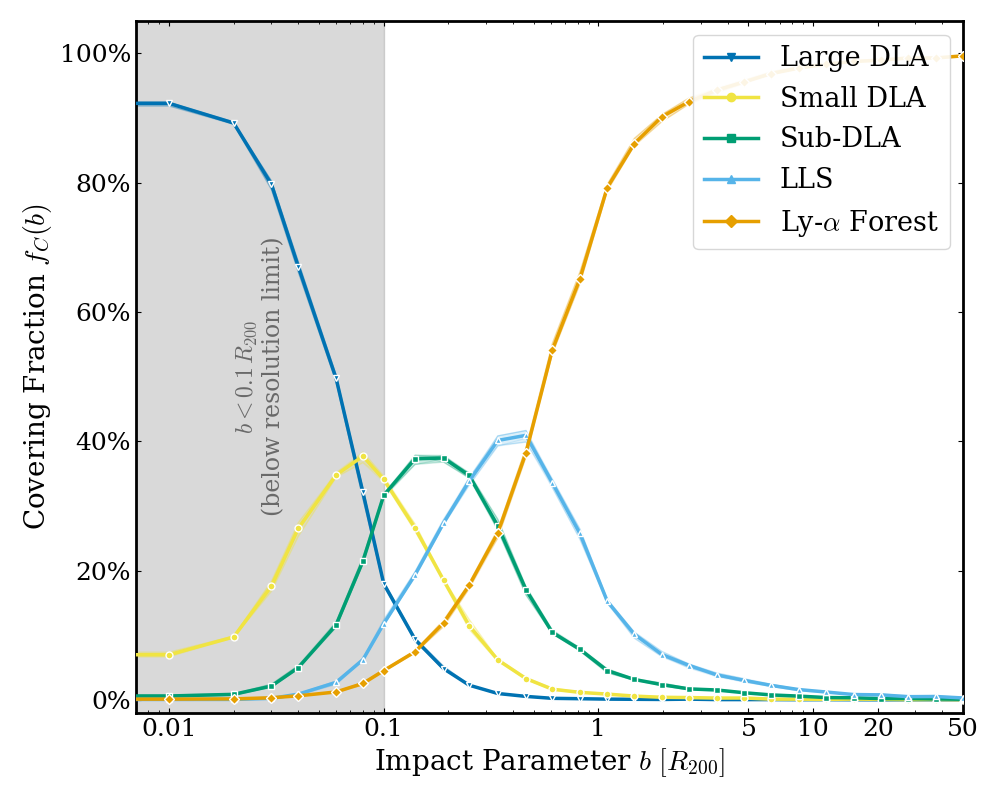

In [12]:
# Plot without the side panel for better visibility of the main panel!

# ==============================================================================
# CELL 5b: COVERING FRACTION PROFILE ONLY (FULL-RANGE SHADING)
# ==============================================================================
fig, ax_main = plt.subplots(figsize=(10, 8))

for cat, style in cat_styles.items():
    data_matrix = fractions_raw[cat]  # (n_runs, n_radii)

    mean_frac = np.mean(data_matrix, axis=0)
    min_frac  = np.min(data_matrix, axis=0)
    max_frac  = np.max(data_matrix, axis=0)

    # Full-range shading
    ax_main.fill_between(
        unique_radii, min_frac, max_frac,
        color=style['color'],
        alpha=0.20,
        zorder=1,
    )

    # Individual runs: thin and faint
    for run_idx in range(data_matrix.shape[0]):
        ax_main.plot(
            unique_radii,
            data_matrix[run_idx, :],
            color=style['color'],
            alpha=0.20,
            lw=0.8,
            ls='-',
            zorder=2,
        )

    # Mean line
    ax_main.plot(
        unique_radii,
        mean_frac,
        color=style['color'],
        lw=2.5,
        ls='-',
        marker=style['marker'],
        ms=5,
        mec='white',
        zorder=3,
    )

# --- Aesthetics ---
#ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])
ax_main.set_xlim(unique_radii[unique_radii > 0].min() * 0.7, 50)

# Resolution-limit shading: b < 0.1 R200 is below the convergence limit
# (conservative, lowest-mass limit; see Appendix resolution tests).
B_RESOLUTION_LIMIT = 0.1
ax_main.axvspan(
    ax_main.get_xlim()[0], B_RESOLUTION_LIMIT,
    color='dimgray', alpha=0.25, zorder=0,
)

# Label the shaded region directly (paper caption fix: keep the legend to
# just the 5 categories; state the b limit as text over the shading instead).
b_lo_shade = ax_main.get_xlim()[0]
x_mid_shade = np.sqrt(b_lo_shade * B_RESOLUTION_LIMIT)  # log-scale midpoint
ax_main.text(
    x_mid_shade, 0.5,
    rf'$b < {B_RESOLUTION_LIMIT:g}\,R_{{200}}$' + '\n(below resolution limit)',
    rotation=90, ha='center', va='center', fontsize=17, color='dimgray',
    zorder=15,
)

ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
if SIM_LABEL:
    ax_main.set_title(rf'Absorber Covering Fraction ({SIM_LABEL})', pad=15)

# --- Legend ---
legend_elements = [
    Line2D(
        [0], [0],
        color=c['color'],
        lw=2.5,
        marker=c['marker'],
        label=c['label'],
    )
    for c in cat_styles.values()
]

ax_main.legend(
    handles=legend_elements,
    loc='upper right',
    frameon=True,
    fontsize=19.5,
    edgecolor='lightgray',
    facecolor='white',
    framealpha=0.9,
)

plt.tight_layout()
out_5b = out_path("Fig3")
fig.savefig(out_5b, bbox_inches='tight')
print(f"saved {out_5b}")
plt.show()


# Ridgeline Plots!

In [13]:
# Ridgeline Plots!
# ==============================================================================
# CELL 7: RIDGELINE — VARIANCE ACROSS RUNS (DENSITY-NORMALIZED, ALIGNED EDGES)
# ==============================================================================

# --------------------------------------------------------------------------
# 0. Configuration
# --------------------------------------------------------------------------
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

for df_run in dfs_runs:
    if 'halo_mass_msun' not in df_run.columns:
        df_run['halo_mass_msun'] = df_run['halo_mass'] * MASS_CONVERSION_FACTOR

# Filter impact parameters: 0.05 to 2.0 R200 (shrinks the shaded
# sub-floor region relative to the earlier b >= 0.0 version).
SELECTED_B = sorted(unique_radii[(unique_radii >= 0.05) & (unique_radii <= 2.0)])
print(f"Impact parameters for ridgeline ({len(SELECTED_B)}):\n  {SELECTED_B}")

# Mass bins
mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**12.0, 10**13.0]
mass_labels = [
    r'$10^{10.0} \leq M_{200} < 10^{10.5} \; M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11.0} \; M_\odot$',
    r'$10^{11.0} \leq M_{200} < 10^{11.5} \; M_\odot$',
    r'$10^{11.5} \leq M_{200} < 10^{12.0} \; M_\odot$',
    r'$10^{12.0} \leq M_{200} < 10^{13.0} \; M_\odot$',
]
n_mass_bins = len(mass_labels)

# Background region colours -- CLASS_COLORS, defined once in CELL 1
c_forest   = CLASS_COLORS['Forest']
c_lls      = CLASS_COLORS['LLS']
c_subdla   = CLASS_COLORS['Sub_DLA']
c_smalldla = CLASS_COLORS['Small_DLA']
c_largedla = CLASS_COLORS['Large_DLA']

# Run colours
run_colors = ['tab:red', 'tab:blue', 'tab:green', 'tab:orange', 'tab:purple']

# Per-ridgeline (per impact-parameter row) colour for that row's own median
# tick + 16-84th percentile shading -- see the "Median / percentile marker"
# section below. Sampled by row index rather than tied to any category
# palette, since a row is one impact parameter, not one absorber class.
row_cmap = plt.cm.viridis

# Resolution convergence limit: skewers at b < 0.1 R200 are not trusted
# (conservative, lowest-mass limit; see Appendix resolution tests).
B_RESOLUTION_LIMIT = 0.1

# ----------------------------------------------------------------------------
# overlap_factor: COSMETIC VERTICAL SCALING.
# Each ridgeline curve is drawn above an integer y-base. With density-per-dex
# normalization the natural curve heights are small (~0.5-2.0), so we multiply
# by overlap_factor to make the curves visually prominent. It does NOT distort
# relative areas: the area between two log N_HI limits equals the fraction of
# skewers in that interval (exactly the covering-fraction quantity).
# Typical good values: 2.0 - 4.0. Bigger = more overlap between rows.
# ----------------------------------------------------------------------------
overlap_factor = 1.8
n_sel          = len(SELECTED_B)

# Histogram definitions (restricted to 16.0 -> 23.0)
num_bins  = 100
hist_bins = np.linspace(16.0, 23.0, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]   # constant since we use linspace


# --------------------------------------------------------------------------
# CORRECTED HISTOGRAM: density per dex (dn / d log N_HI / N_total)
# --------------------------------------------------------------------------
def density_hist(values, bins, tot_skewers):
    """
    Returns probability density per unit log N_HI, normalized to the
    curve's OWN total (tot_skewers = the number of HCD-bearing skewers at
    this (b, mass bin, run), not all skewers at that b -- so every row's
    curve integrates to 1 over the full range regardless of how common an
    HCD is at that b. (Previously normalized to all skewers including
    forest, so area encoded incidence; reverted per the paper caption note
    on Fig. nhi_ridge_allmasses -- shape, not incidence, is what this plot
    is meant to show, and incidence is already Fig. hcds_percent_vs_b.)

    Height in each bin = (counts_in_bin / tot_skewers) / bin_width

    Properties:
    - Integral over the full range = 1 for any (b, mass bin, run) that has
      at least one HCD-bearing skewer.
    - Integral over any sub-range [a, b] = fraction of THIS row's HCD
      population falling in that log N_HI interval.
    """
    if len(values) < 2 or tot_skewers == 0:
        return np.zeros(len(bins) - 1)

    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]
    return counts / (tot_skewers * bw)


# --------------------------------------------------------------------------
# Generic ridgeline painter (density-normalized + aligned category edges)
# --------------------------------------------------------------------------
def paint_ridgeline(ax, dfs_runs, selected_b, mass_low=None, mass_high=None,
                    title_text='', show_legend=True, b_resolution_limit=B_RESOLUTION_LIMIT):

    # Background spans — boundary at 21.0 (CONSISTENT with covering fraction)
    ax.axvspan(16.0, 17.2, color=c_forest,   zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls,      zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla,   zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)

    # Threshold markers (now at 21.0 instead of 21.5)
    for xv in [17.2, 19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    # Regime Text Boxes at the top of the plot
    text_y_pos = 0.98
    bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7, edgecolor="none")
    ax.text(18.10, text_y_pos, 'LLS', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=13, bbox=bbox_props, zorder=10)
    ax.text(19.65, text_y_pos, 'Sub-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=13, bbox=bbox_props, zorder=10)
    ax.text(20.65, text_y_pos, 'Small-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=13, bbox=bbox_props, zorder=10)
    ax.text(22.00, text_y_pos, 'Large-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=13, bbox=bbox_props, zorder=10)

    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # --- Resolution-limit marker -------------------------------------------
    # Impact parameters below the convergence limit (b < 0.1 R200, the most
    # conservative/lowest-mass limit; see Appendix resolution tests) are not
    # trusted. Rather than shade the excluded rows, the boundary between the
    # last excluded row and the first trusted one is marked with a single
    # dashed line plus a text annotation sitting just above it.
    if b_resolution_limit is not None:
        b_arr = np.asarray(selected_b, dtype=float)
        excluded = np.where(b_arr < b_resolution_limit)[0]
        if len(excluded) > 0:
            y_boundary = excluded.max() + 1.0
            ax.axhline(
                y_boundary, color='dimgray', ls='--', lw=1.6, zorder=2,
            )
            ax.text(
                23.0, y_boundary + 0.10,
                rf'$b \lesssim {b_resolution_limit:g}\,R_{{200}}$',
                ha='right', va='bottom', fontsize=13, color='dimgray',
                zorder=20,
            )

    y_ticks  = []
    y_labels = []

    for i_b, b_val in enumerate(selected_b):
        b_round = np.round(b_val, 2)
        y_base  = i_b
        row_c   = row_cmap(i_b / max(len(selected_b) - 1, 1))

        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=0.8, alpha=0.3, zorder=1)

        hist_stack  = []
        all_pool    = []   # FULL population (HCD + forest), for the median/IQR fix below

        for r_idx, df_run in enumerate(dfs_runs):
            if mass_low is not None and mass_high is not None:
                df_mass = df_run[
                    (df_run['halo_mass_msun'] >= mass_low) &
                    (df_run['halo_mass_msun'] <  mass_high)
                ]
            else:
                df_mass = df_run

            df_b   = df_mass[df_mass['r_mult_round'] == b_round]

            # Pipeline forces sub-threshold to 0.0, so valid contains only HCDs.
            valid  = df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values

            # Density per dex, normalized by the row's OWN total (the number
            # of HCD-bearing skewers here), not by all skewers at this b.
            n_hcd = len(valid)
            mask_hist = (valid >= 16.0) & (valid <= 23.0)
            hist_dens = density_hist(valid[mask_hist], hist_bins, n_hcd)
            hist_stack.append(hist_dens)
            all_pool.append(df_b['log_n_hi'].values)

        hist_stack = np.array(hist_stack)
        all_pooled = np.concatenate(all_pool) if all_pool else np.array([])

        # --- Plot individual runs as thin transparent lines ---
        for r_idx in range(len(dfs_runs)):
            scaled = hist_stack[r_idx] * overlap_factor

            ax.plot(
                x_hist, y_base + scaled,
                color=run_colors[r_idx % len(run_colors)],
                lw=0.8, alpha=0.4, ls='-', zorder=i_b + 3,
            )

        # --- Full-range envelope across the 5 realizations ---
        mean_hist = np.mean(hist_stack, axis=0)
        min_hist  = np.min(hist_stack, axis=0)
        max_hist  = np.max(hist_stack, axis=0)

        mean_scaled = mean_hist * overlap_factor
        lo_scaled   = min_hist * overlap_factor
        hi_scaled   = max_hist * overlap_factor

        # Shading
        ax.fill_between(
            x_hist, y_base + lo_scaled, y_base + hi_scaled,
            color='gray', alpha=0.20, zorder=i_b + 4,
        )

        # Mean line (solid black)
        ax.plot(
            x_hist, y_base + mean_scaled,
            color='black', lw=1.6, ls='-', zorder=i_b + 6,
        )

        # --- Median / 16-84th percentile marker for this row -----------------
        # Percentiles of the FULL pooled population (HCD-bearing skewers AND
        # the forest ones the pipeline zeros out) -- not just the HCD subset,
        # so a row where most skewers have no HCD at all shows that honestly
        # (median/IQR collapsing below 16, i.e. off the log N_HI axis, is the
        # correct answer there, not a bug).
        #
        # Embedded IN the ridge rather than a free-floating box: the IQR is
        # shaded under the MEAN CURVE ITSELF (fill_between's `where` mask
        # naturally clips to whatever part of [p16, p84] actually falls
        # inside the plotted x-range, including "none of it"), and the
        # median tick rises only up to the curve's own height at p50 -- so
        # both read as a highlighted portion of the curve, not a second,
        # unrelated band competing with the full-range envelope. Coloured
        # by row_c (this ridge's own colour, see row_cmap above) rather than
        # a single fixed colour, so overlapping ridges' median/IQR markers
        # stay visually distinct -- explained in the separate colour key
        # added to the legend below, not by name in the main legend.
        if all_pooled.size >= 5:
            p16, p50, p84 = np.percentile(all_pooled, [16, 50, 84])
            ax.fill_between(
                x_hist, y_base, y_base + mean_scaled,
                where=(x_hist >= p16) & (x_hist <= p84),
                color=row_c, alpha=0.45, zorder=i_b + 5,
            )
            if 16.0 <= p50 <= 23.0:
                y_p50 = np.interp(p50, x_hist, mean_scaled)
                ax.plot(
                    [p50, p50], [y_base, y_base + y_p50],
                    color=row_c, lw=2.2, ls='-', zorder=i_b + 6.5,
                )

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=13)
    ax.set_xlim(17.2, 23.0)
    ax.set_ylim(-0.5, len(selected_b) - 1 + overlap_factor + 0.5)

    if title_text:
        ax.text(
            0.98, 0.90, title_text, transform=ax.transAxes,
            fontsize=13, ha='right', va='top',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'),
            zorder=30,
        )

    if show_legend:
        mean_line  = Line2D([0], [0], color='black', lw=1.6, label='Mean')
        band_patch = patches.Patch(
            facecolor='gray', alpha=0.25, edgecolor='gray',
            label=rf'Full range ({len(dfs_runs)} runs)',
        )
        all_handles = [mean_line, band_patch]

        if b_resolution_limit is not None:
            b_arr = np.asarray(selected_b, dtype=float)
            if np.any(b_arr < b_resolution_limit):
                res_line = Line2D(
                    [0], [0], color='dimgray', ls='--', lw=1.6,
                    label=rf'$b \lesssim {b_resolution_limit:g}\,R_{{200}}$',
                )
                all_handles.append(res_line)

        leg = ax.legend(
            handles=all_handles, loc='upper right', ncol=1,
            frameon=True, fontsize=13,
            bbox_to_anchor=(0.99, 0.85),
            facecolor='white', framealpha=0.95,
            edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5,
        )
        leg.set_zorder(100)

        # --- separate colour key for the per-ridgeline median/IQR colouring
        # (row_c above) -- deliberately its own legend, outside the main box,
        # since colour there identifies WHICH ridge, not a shared category.
        row_norm = Normalize(vmin=0, vmax=max(len(selected_b) - 1, 1))
        row_sm = ScalarMappable(norm=row_norm, cmap=row_cmap)
        row_sm.set_array([])
        cax = ax.inset_axes([1.02, 0.0, 0.025, 1.0])
        cbar = ax.figure.colorbar(row_sm, cax=cax)
        cbar.set_ticks([])
        cbar.set_label(
            'Median & 16-84th percentile\ncolour (per ridge)',
            fontsize=11, rotation=90, labelpad=8,
        )


Impact parameters for ridgeline (13):
  [0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


saved /home/vroberto/FakeSpectra_DLAs/definitives/Fig5.pdf


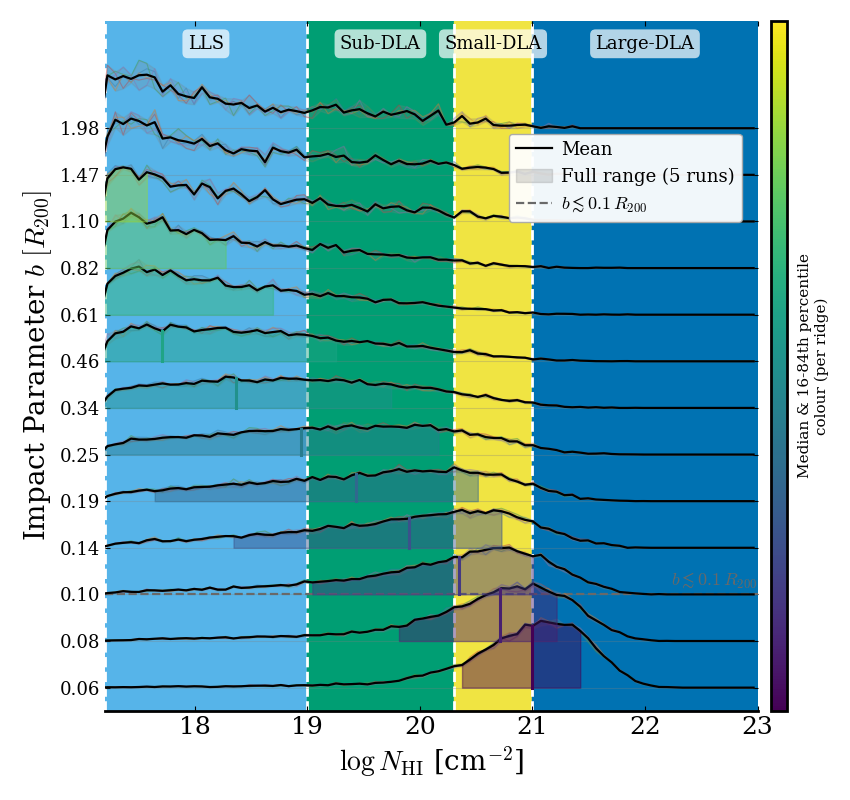

In [14]:
# ==========================================================================
# PLOT A: RIDGELINE — ALL MASSES COMBINED
# ==========================================================================
plt.close('all')
fig_width_all  = 8.5   # sized to fit a single (paper) column
fig_height_all = max(8, 0.60 * n_sel)
fig_all, ax_all = plt.subplots(figsize=(fig_width_all, fig_height_all))

paint_ridgeline(
    ax_all, dfs_runs, SELECTED_B,
    mass_low=None, mass_high=None,
    title_text=SIM_LABEL,          # simulation name, empty for TNG50-2
    show_legend=True,
)

ax_all.set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]")
ax_all.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')


plt.tight_layout()
out_ridge = out_path("Fig5")
fig_all.savefig(out_ridge, bbox_inches='tight')
print(f"saved {out_ridge}")

plt.show()


In [15]:
# ==============================================================================
# CELL 7c: MEDIAN log N_HI(b) AND 16-84 PERCENTILE WIDTH (for Sec. 3.1.2 text)
# ==============================================================================
# Same HCD-bearing selection as the ridgeline (log_n_hi > 1.0), computed per
# run and then summarized as mean [min-max] across the 5 realizations.

REP_RADII = [0.0, 0.34, 1.10]   # core, transition, ~R200 (as discussed in text)

nhi_stats_rows = []
for b_val in SELECTED_B:
    b_round = np.round(b_val, 2)
    med_runs, w1684_runs = [], []
    for df_run in dfs_runs:
        df_b  = df_run[df_run['r_mult_round'] == b_round]
        valid = df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values
        if len(valid) > 0:
            med_runs.append(np.median(valid))
            p16, p84 = np.percentile(valid, [16, 84])
            w1684_runs.append(p84 - p16)
    if med_runs:
        nhi_stats_rows.append((
            b_val,
            np.mean(med_runs), np.min(med_runs), np.max(med_runs),
            np.mean(w1684_runs), np.min(w1684_runs), np.max(w1684_runs),
        ))

print(f"{'b [R200]':>10} {'median':>8} {'[min-max]':>14} {'P16-84 width':>15} {'[min-max]':>14}")
for b_val, m_mean, m_min, m_max, w_mean, w_min, w_max in nhi_stats_rows:
    flag = "  <-- representative" if any(abs(b_val - r) < 1e-6 for r in REP_RADII) else ""
    print(f"{b_val:10.2f} {m_mean:8.2f} [{m_min:5.2f}-{m_max:5.2f}] "
          f"{w_mean:15.2f} [{w_min:5.2f}-{w_max:5.2f}]{flag}")

print("\nRepresentative radii for the paper text:")
for b_val, m_mean, m_min, m_max, w_mean, w_min, w_max in nhi_stats_rows:
    if any(abs(b_val - r) < 1e-6 for r in REP_RADII):
        print(f"  b = {b_val:.2f} R200: median logNHI = {m_mean:.2f} [{m_min:.2f}-{m_max:.2f}], "
              f"16-84 width = {w_mean:.2f} [{w_min:.2f}-{w_max:.2f}] dex")


  b [R200]   median      [min-max]    P16-84 width      [min-max]
      0.06    21.00 [21.00-21.01]            1.10 [ 1.08- 1.11]
      0.08    20.73 [20.71-20.74]            1.41 [ 1.37- 1.43]
      0.10    20.40 [20.39-20.42]            1.82 [ 1.81- 1.87]
      0.14    20.02 [20.00-20.04]            2.09 [ 2.04- 2.12]
      0.19    19.65 [19.61-19.68]            2.27 [ 2.24- 2.30]
      0.25    19.29 [19.26-19.31]            2.25 [ 2.22- 2.26]
      0.34    18.88 [18.85-18.92]            2.16 [ 2.11- 2.20]  <-- representative
      0.46    18.52 [18.50-18.54]            2.09 [ 2.06- 2.13]
      0.61    18.25 [18.23-18.28]            1.96 [ 1.92- 1.99]
      0.82    18.19 [18.18-18.20]            1.96 [ 1.93- 2.00]
      1.10    18.20 [18.18-18.21]            2.08 [ 1.99- 2.11]  <-- representative
      1.47    18.18 [18.13-18.24]            2.10 [ 2.07- 2.15]
      1.98    18.15 [18.08-18.17]            2.11 [ 2.06- 2.19]

Representative radii for the paper text:
  b = 0.34 R200: med

saved /home/vroberto/FakeSpectra_DLAs/definitives/covering_fraction_profile_by_mass_TNG50-2.pdf


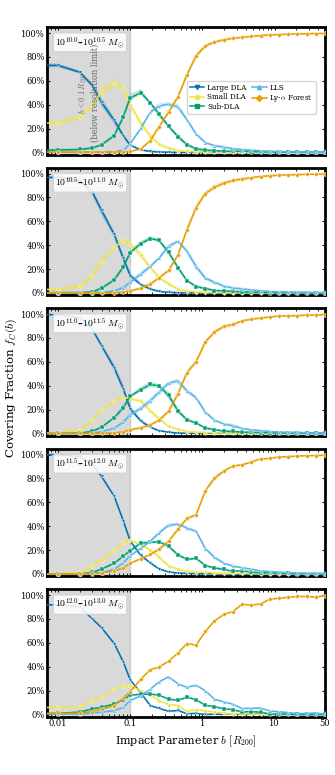

In [16]:
# ==============================================================================
# CELL 8: COVERING FRACTION PROFILES SPLIT BY HALO MASS BIN
# ==============================================================================
# Reuses: dfs_runs, unique_radii, cat_styles, n_runs, mass_edges, HUBBLE_H
# Five mass-bin panels, stacked one above the other in a single column.
# The shared category legend is placed inside the first panel.

# Ensure the physical-mass column exists (idempotent w.r.t. Cell 7)
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H
for df_run in dfs_runs:
    if 'halo_mass_msun' not in df_run.columns:
        df_run['halo_mass_msun'] = df_run['halo_mass'] * MASS_CONVERSION_FACTOR

# Resolution convergence limit, same convention (and value) as CELL 5b's
# single-panel covering-fraction figure: b < 0.1 R200 is below the
# convergence limit (conservative, lowest-mass limit; see Appendix
# resolution tests).
B_RESOLUTION_LIMIT = 0.1

mass_bin_titles = [
    r'$10^{10.0}$–$10^{10.5}\,M_\odot$',
    r'$10^{10.5}$–$10^{11.0}\,M_\odot$',
    r'$10^{11.0}$–$10^{11.5}\,M_\odot$',
    r'$10^{11.5}$–$10^{12.0}\,M_\odot$',
    r'$10^{12.0}$–$10^{13.0}\,M_\odot$',
]
n_mass_bins = len(mass_bin_titles)

# --------------------------------------------------------------------------
# Fraction profiles (n_runs, n_radii) per category for a mass-selected subset.
# Empty (bin, b) cells -> NaN so they are ignored in mean/std and simply not drawn.
# --------------------------------------------------------------------------
def compute_fraction_profiles(dfs, radii, mass_low=None, mass_high=None):
    out = {cat: [] for cat in cat_styles}
    counts = []

    for df_run in dfs:
        if mass_low is not None:
            df_m = df_run[
                (df_run['halo_mass_msun'] >= mass_low) &
                (df_run['halo_mass_msun'] < mass_high)
            ]
        else:
            df_m = df_run

        run_fracs = {cat: [] for cat in cat_styles}
        run_counts = []

        for b_val in radii:
            df_b = df_m[df_m['r_mult_round'] == b_val]
            tot = len(df_b)
            run_counts.append(tot)

            if tot > 0:
                nhi = df_b['log_n_hi']

                run_fracs['Large_DLA'].append(
                    len(nhi[nhi >= 21.0]) / tot
                )
                run_fracs['Small_DLA'].append(
                    len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot
                )
                run_fracs['Sub_DLA'].append(
                    len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot
                )
                run_fracs['LLS'].append(
                    len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot
                )
                run_fracs['Forest'].append(
                    len(nhi[nhi < 17.2]) / tot
                )
            else:
                for cat in cat_styles:
                    run_fracs[cat].append(np.nan)

        for cat in cat_styles:
            out[cat].append(run_fracs[cat])

        counts.append(run_counts)

    for cat in cat_styles:
        out[cat] = np.array(out[cat])

    return out, np.array(counts)


# --------------------------------------------------------------------------
# 5x1 column: one panel per mass bin, stacked for a single paper column
# --------------------------------------------------------------------------
panel_specs = [
    (mass_edges[i], mass_edges[i+1], mass_bin_titles[i])
    for i in range(n_mass_bins)
]

COLUMN_W_IN = 3.35   # single-column width (MNRAS-style)
PANEL_H_IN  = 1.55   # per-panel height

fig, axes = plt.subplots(
    n_mass_bins, 1,
    figsize=(COLUMN_W_IN, PANEL_H_IN * n_mass_bins),
    sharex=True,
    sharey=True
)

for panel_idx, (ax, (m_lo, m_hi, title)) in enumerate(
    zip(axes, panel_specs)
):
    profiles, counts = compute_fraction_profiles(
        dfs_runs, unique_radii, m_lo, m_hi
    )

    for cat, style in cat_styles.items():
        data = profiles[cat]  # (n_runs, n_radii)

        with np.errstate(invalid='ignore'):
            mean_frac = np.nanmean(data, axis=0)
            min_frac  = np.nanmin(data, axis=0)
            max_frac  = np.nanmax(data, axis=0)

        ax.fill_between(
            unique_radii,
            min_frac,
            max_frac,
            color=style['color'],
            alpha=0.18,
            zorder=1,
        )

        ax.plot(
            unique_radii,
            mean_frac,
            color=style['color'],
            lw=1.1,
            ls='-',
            marker=style['marker'],
            ms=2.5,
            mec='white',
            mew=0.3,
            zorder=3,
        )

    # Typical sample size per impact parameter
    # (median over populated b, all runs)
    populated = counts[counts > 0]
    med_n = int(np.median(populated)) if populated.size else 0

    ax.text(
        0.03, 0.94,
        title,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=7,
        fontweight='bold',
        bbox=dict(
            boxstyle='round,pad=0.2',
            facecolor='white',
            alpha=0.85,
            edgecolor='lightgray'
        ),
        zorder=10
    )

    # ax.text(
    #     0.03, 0.70,
    #     rf'$\sim${med_n:,} skewers$/b$',
    #     transform=ax.transAxes,
    #     ha='left',
    #     va='top',
    #     fontsize=5.5,
    #     color='dimgray',
    #     zorder=10
    # )

    ax.set_xscale('log')
    ax.set_ylim(-0.02, 1.05)

    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(xmax=1.0)
    )

    ax.tick_params(
        labelsize=6,
        length=2.5,
        pad=1.5
    )

    ax.set_xticks([0.01, 0.1, 1.0, 10.0, 50.0])
    ax.set_xticklabels(['0.01', '0.1', '1', '10', '50'])

    ax.set_xlim(
        unique_radii[unique_radii > 0].min() * 0.7,
        50
    )

    # Resolution-floor shading, same convention as CELL 5b's single-panel
    # covering-fraction figure. Drawn in every panel (they share the x-axis);
    # the explanatory text is only added once, in the top panel, to avoid
    # cluttering five stacked, height-constrained subpanels.
    ax.axvspan(
        ax.get_xlim()[0], B_RESOLUTION_LIMIT,
        color='dimgray', alpha=0.25, zorder=0,
    )
    if panel_idx == 0:
        b_lo_shade = ax.get_xlim()[0]
        x_mid_shade = np.sqrt(b_lo_shade * B_RESOLUTION_LIMIT)
        ax.text(
            x_mid_shade, 0.5,
            rf'$b < {B_RESOLUTION_LIMIT:g}\,R_{{200}}$'
            + '\n(below resolution limit)',
            rotation=90, ha='center', va='center', fontsize=6,
            color='dimgray', zorder=15,
        )

    # ----------------------------------------------------------------------
    # Shared category legend inside the first panel
    # ----------------------------------------------------------------------
    if panel_idx == 0:
        legend_elements = [
            Line2D(
                [0], [0],
                color=c['color'],
                lw=1.1,
                marker=c['marker'],
                ms=3.0,
                label=c['label']
            )
            for c in cat_styles.values()
        ]

        ax.legend(
            handles=legend_elements,
            loc='center right',
            bbox_to_anchor=(0.98, 0.45),
            ncol=2,
            frameon=True,
            fontsize=5.2,
            edgecolor='lightgray',
            facecolor='white',
            framealpha=0.9,
            handletextpad=0.35,
            columnspacing=0.8,
            labelspacing=0.2,
            borderpad=0.4,
        )


# --- Shared labels ---
fig.supylabel(
    r'Covering Fraction $f_C(b)$',
    fontsize=8.5,
    x=0.01
)

if SIM_LABEL:
    fig.suptitle(
        rf'Absorber Covering Fraction by Halo Mass ({SIM_LABEL})',
        fontsize=8.5,
        y=0.998
    )

axes[-1].set_xlabel(
    r'Impact Parameter $b \ [R_{200}]$',
    fontsize=8
)

# Manual margins
fig.subplots_adjust(
    left=0.14,
    right=0.97,
    top=0.965,
    bottom=0.075,
    hspace=0.10
)

out_massbin = out_path(f"covering_fraction_profile_by_mass_{SIM_NAME}")
fig.savefig(out_massbin, bbox_inches='tight')
print(f"saved {out_massbin}")
plt.show()


### Let's see now the individual behavior of the absorptions for a choosen halo to a choosen impact parameter

In [10]:
### Halo overview: HI map + the very same skewers' absorption, in one figure
# ==============================================================================
# CELL 10: COMBINED FIGURE
#   top    -> HI column-density map (z projection) with HCD/DLA contours,
#             R_200, and the 24 sightlines drawn where they actually pass
#   bottom -> the spectra of those same 24 sightlines
# Everything is driven by the knobs in STEP 0, so halo and radii stay free.
# ==============================================================================
import h5py
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ------------------------------------------------------------------
# STEP 0. Every knob in one place
# ------------------------------------------------------------------
# -- halo selection --
SELECT_SEED   = 0          # only used when HALO_ID is None
# 265 is a TNG50-2 FoF id; for the other simulations draw one from the mass bin
HALO_ID       = 265 if SIM_NAME == 'TNG50-2' else None
MASS_LO_LOG   = 11.5       # mass bin, log10(M_200 / M_sun), physical
MASS_HI_LOG   = 12.0
# -- impact parameters: (requested b in R_200, colour). Add a third if you like --
B_SETS        = [(0.01, 'tab:blue'),
                 (0.2,  'tab:red')]
# -- bottom panel --
SHOW_MEDIAN   = False      # thick line = median of each set
VEL_WINDOW    = 2000       # x half-width in km/s (None = full box)
# -- map / snapshot --
SNAP_NUM      = 25
STORAGE       = f'/home/STORAGE/{SIM_NAME}'
BOX_HALF_R200 = 3.0        # map half-width, in units of R_200
NPIX          = 256        # pixels per side
SMOOTH_SIGMA  = 1.0        # Gaussian smoothing in pixels (0 = off)
X_HYDROGEN    = 0.76       # hydrogen mass fraction, same value the pipeline uses
MAX_CHUNKS    = None       # e.g. 8 for a quick test; None = every chunk
USE_CACHE     = True       # skip re-reading the snapshot when only tweaking the plot
# -- constants --
MSUN_G, MPROTON_G, KPC_CM = 1.989e33, 1.6726e-24, 3.0857e21

# ------------------------------------------------------------------
# STEP 1. Take one run and pick the halo inside the mass bin
# ------------------------------------------------------------------
df_run = dfs_runs[0]
if 'halo_mass_msun' not in df_run.columns:
    df_run['halo_mass_msun'] = df_run['halo_mass'] * MASS_CONVERSION_FACTOR
# Shared velocity grid lives in df.attrs, not in the rows (new schema).
if 'v_grid' not in df_run.attrs:
    raise KeyError("df.attrs has no 'v_grid' -- file not written by the current pipeline.")
v_grid = np.asarray(df_run.attrs['v_grid'])

in_bin = df_run[(df_run['halo_mass_msun'] >= 10**MASS_LO_LOG) &
                (df_run['halo_mass_msun'] <  10**MASS_HI_LOG)]
halo_ids_in_bin = np.sort(in_bin['halo_id'].unique())
if len(halo_ids_in_bin) == 0:
    raise ValueError(f"No halo in 10^{MASS_LO_LOG}-10^{MASS_HI_LOG} M_sun in this run.")
if HALO_ID is None:
    HALO_ID = int(np.random.default_rng(SELECT_SEED).choice(halo_ids_in_bin))

df_halo        = df_run[df_run['halo_id'] == HALO_ID]
halo_mass_msun = df_halo['halo_mass_msun'].iloc[0]
print(f"Mass bin 10^{MASS_LO_LOG}-10^{MASS_HI_LOG}: {len(halo_ids_in_bin)} halos")
print(f"  -> halo_id = {HALO_ID} | log M_200 = {np.log10(halo_mass_msun):.2f} "
      f"| {len(df_halo)} skewers")

# ------------------------------------------------------------------
# STEP 2. Snap each requested b onto the real grid and grab its 12 skewers
# ------------------------------------------------------------------
# The grid is 0.0 plus 30 log-spaced values in [0.01, 50], so round numbers are
# usually NOT on it. We match the RAW r_multiplier (r_mult_round would merge
# 0.0100/0.0134 and 0.0180/0.0241 and return 24 skewers per set).
avail_b = np.sort(df_halo['r_multiplier'].unique())
avail_b = avail_b[avail_b > 0]
selected = []
for target_b, color in B_SETS:
    b_exact = float(avail_b[np.argmin(np.abs(avail_b - target_b))])
    if any(np.isclose(b_exact, s['b_exact']) for s in selected):
        raise ValueError(f"b={target_b} snapped onto {b_exact:.4f}, already in use. "
                         f"Available: {np.round(avail_b, 4)}")
    d = df_halo[np.isclose(df_halo['r_multiplier'], b_exact)]
    selected.append({'target': target_b, 'b_exact': b_exact, 'color': color, 'df': d})
    print(f"  b = {target_b} -> grid {b_exact:.4f} R_200 "
          f"({d['impact_kpc'].iloc[0]:.2f} ckpc/h) | {len(d)} skewers "
          f"| HCD: {int(d['is_hcd'].sum())}/{len(d)}")

# ------------------------------------------------------------------
# STEP 3. Halo position from the FoF catalogue
# ------------------------------------------------------------------
# Same logic as utils.HaloFinder: halo_id is the GLOBAL index across the group
# chunks, i.e. exactly the object the pipeline sampled.
group_dir = os.path.join(STORAGE, f'groups_{SNAP_NUM:03d}')
with h5py.File(os.path.join(group_dir, f'fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5'), 'r') as f:
    hdr = f['Header'].attrs
    n_group_files = int(hdr.get('NumFiles', hdr.get('NumFilesPerSnapshot', 1)))
    BOX, A_SC, HUB = float(hdr['BoxSize']), float(hdr['Time']), float(hdr['HubbleParam'])

offset, halo_props = 0, None
for i in range(n_group_files):
    gf = os.path.join(group_dir, f'fof_subhalo_tab_{SNAP_NUM:03d}.{i}.hdf5')
    if not os.path.exists(gf):
        continue
    with h5py.File(gf, 'r') as f:
        if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
            continue
        n_here = len(f['Group']['Group_M_Crit200'])
        if HALO_ID < offset + n_here:
            j = int(HALO_ID - offset)
            halo_props = dict(cm=np.array(f['Group']['GroupPos'][j], dtype=float),
                              r200=float(f['Group']['Group_R_Crit200'][j]),
                              mass=float(f['Group']['Group_M_Crit200'][j]))
            break
        offset += n_here
if halo_props is None:
    raise ValueError(f"halo_id {HALO_ID} not found in the group catalogue.")

CM, R200 = halo_props['cm'], halo_props['r200']
HALF = BOX_HALF_R200 * R200                       # map half-width, ckpc/h
print(f"\nHalo centre = {np.round(CM,1)} ckpc/h | R_200 = {R200:.2f} ckpc/h")
print(f"Map = +-{HALF:.1f} ckpc/h ({2*HALF/HUB*A_SC:.1f} physical kpc across)")

# ------------------------------------------------------------------
# STEP 4. Read the gas cells inside the box (cached across re-runs)
# ------------------------------------------------------------------
# Reading 128 chunks takes minutes; the cache lets you re-run this cell to
# tweak the figure without touching the disk again.
_cache_key = (SIM_NAME, SNAP_NUM, HALO_ID, BOX_HALF_R200, MAX_CHUNKS)
if USE_CACHE and '_gas_cache' in globals() and _gas_cache.get('key') == _cache_key:
    pos_box, mass_box, fhi_box, has_hi = (_gas_cache['pos'], _gas_cache['mass'],
                                          _gas_cache['fhi'], _gas_cache['has_hi'])
    print(f"\nUsing cached gas cells ({len(pos_box):,}).")
else:
    snap_dir = os.path.join(STORAGE, f'snapdir_{SNAP_NUM:03d}')
    with h5py.File(os.path.join(snap_dir, f'snap_{SNAP_NUM:03d}.0.hdf5'), 'r') as f:
        n_chunks = int(f['Header'].attrs['NumFilesPerSnapshot'])
    n_scan = n_chunks if MAX_CHUNKS is None else min(MAX_CHUNKS, n_chunks)
    print(f"\nScanning {n_scan}/{n_chunks} snapshot chunks...")

    pos_box, mass_box, fhi_box, has_hi = [], [], [], True
    for i in range(n_scan):
        sf = os.path.join(snap_dir, f'snap_{SNAP_NUM:03d}.{i}.hdf5')
        if not os.path.exists(sf):
            continue
        with h5py.File(sf, 'r') as f:
            if 'PartType0' not in f:
                continue
            g = f['PartType0']
            d = g['Coordinates'][:] - CM
            d -= BOX * np.round(d / BOX)          # minimum image: safe at box edges
            m = np.all(np.abs(d) <= HALF, axis=1)
            if not m.any():
                continue
            pos_box.append(d[m])
            mass_box.append(g['Masses'][:][m])    # 1e10 M_sun/h
            if 'NeutralHydrogenAbundance' in g:
                fhi_box.append(g['NeutralHydrogenAbundance'][:][m])
            else:
                has_hi = False
        if (i + 1) % 16 == 0 or i == n_scan - 1:
            print(f"  chunk {i+1:>3}/{n_scan} | {sum(len(p) for p in pos_box):,} cells so far")

    if not pos_box:
        raise RuntimeError("No gas cell in the box -- check STORAGE / SNAP_NUM.")
    pos_box  = np.concatenate(pos_box)
    mass_box = np.concatenate(mass_box)
    fhi_box  = np.concatenate(fhi_box) if has_hi else np.ones(len(mass_box))
    print(f"  -> {len(pos_box):,} gas cells inside the box")
    if not has_hi:
        print("  ! NeutralHydrogenAbundance absent: showing TOTAL hydrogen instead")
    _gas_cache = dict(key=_cache_key, pos=pos_box, mass=mass_box,
                      fhi=fhi_box, has_hi=has_hi)

# ------------------------------------------------------------------
# STEP 5. Project along z -> HI column density [cm^-2]
# ------------------------------------------------------------------
# Nearest-grid-point deposition of each cell's HI mass: a mass histogram, not a
# Voronoi rendering, so pixel values are indicative and will NOT match the
# sightline N_HI cell for cell (the map has all HI, the skewers only the HCD).
edges     = np.linspace(-HALF, HALF, NPIX + 1)
m_hi_msun = mass_box * 1e10 / HUB * X_HYDROGEN * fhi_box
H, _, _   = np.histogram2d(pos_box[:, 0], pos_box[:, 1],
                           bins=[edges, edges], weights=m_hi_msun)
if SMOOTH_SIGMA > 0:
    H = gaussian_filter(H, SMOOTH_SIGMA)
# pixel side in PHYSICAL cm: ckpc/h -> /h -> comoving kpc -> x a -> cm
pix_cm = (2 * HALF / NPIX) / HUB * A_SC * KPC_CM
N_HI   = H * MSUN_G / MPROTON_G / pix_cm**2
logN   = np.log10(np.where(N_HI > 0, N_HI, np.nan))
print(f"Map log N_HI: {np.nanmin(logN):.2f} .. {np.nanmax(logN):.2f}")


Mass bin 10^11.5-10^12.0: 150 halos
  -> halo_id = 265 | log M_200 = 11.54 | 363 skewers
  b = 0.01 -> grid 0.0100 R_200 (1.47 ckpc/h) | 12 skewers | HCD: 12/12
  b = 0.2 -> grid 0.1886 R_200 (27.73 ckpc/h) | 12 skewers | HCD: 6/12

Halo centre = [13783.1 23854.  13967.4] ckpc/h | R_200 = 147.02 ckpc/h
Map = +-441.1 ckpc/h (324.9 physical kpc across)

Scanning 128/128 snapshot chunks...
  chunk  16/128 | 63,597 cells so far
  chunk  64/128 | 99,397 cells so far
  chunk 128/128 | 148,074 cells so far
  -> 148,074 gas cells inside the box
Map log N_HI: 9.45 .. 20.93
